In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Context effect — what a persona / frame adds to the model's default preferences

Nir's list (2026-10-11), item 8. No new runs. The reference is the default (`shopping` frame, no
contract). A context — a persona or frame (`student`, `windows`, `bare`, ...), or an explicit contract
for comparison — changes the model's preferences. Everything here is the **additive** view, with the
default as **0**:

- **per feature level:** `Δw = w1 − w0` for the 11 FeatureBT weights (centred within each feature);
- **per laptop:** `Δu = u1 − u0` for the 45 laptops — either the position-corrected **Borda** score
  (model-free) or the **sum of the laptop's three feature weights** (the additive model's view).

(A multiplicative view, default = 1, was tried on 2026-10-11 and dropped: BT identifies only
differences between levels, so a weight or a utility has no natural zero and ratios explode near it.)

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from src.bt import FeatureBT

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/context"
os.makedirs(FIGDIR, exist_ok=True)
LEVELS = {"brand": ["ASUS", "Apple", "Dell", "HP", "Lenovo"], "screen": ["13-inch", "14-inch", "16-inch"],
          "ram": ["4GB", "8GB", "16GB"]}
LV = [(f, l) for f in LEVELS for l in LEVELS[f]]
FOLDERS = ["data/laptops_robustness", "data/laptops_robustness_gemma", "data/laptops_persona"]
FRAMES = ["bare", "student_only", "no_money", "student", "role_none", "role_student", "windows", "designer", "editor"]
CONTRACTS = ["screen=13-inch", "screen=14-inch", "screen=16-inch", "ram=4GB", "ram=8GB", "ram=16GB"]
# multi-requirement contracts (2026-10-12): the two doubles, and the Dell path (qwen-32B only so far)
MULTI = ["ram=8GB+screen=14-inch", "ram=4GB+screen=14-inch",
         "brand=Dell", "brand=Dell+screen=14-inch", "brand=Dell+ram=8GB", "brand=Dell+ram=8GB+screen=14-inch"]
MODEL_ORDER = [("qwen", s) for s in ("0.5", "7", "32", "72")] + [("gemma", s) for s in ("1", "4", "12", "27")]


def load():
    """{(family, size, context): w vector (11)}. context = frame name (no contract) or constraints_id
    (shopping frame); 'default' = shopping, no contract."""
    W = {}
    for base in FOLDERS:
        for r in sorted(os.listdir(base)):
            cf, sc = f"{base}/{r}/config.json", f"{base}/{r}/scores.csv"
            if not (os.path.isfile(cf) and os.path.isfile(sc)):
                continue
            c = json.load(open(cf))
            m = (c["model_family"], str(c["model_size"]))
            if m not in MODEL_ORDER:
                continue
            fr, cid = c["frame"]["name"], c["constraints_id"]
            if fr == "shopping":
                ctx = "default" if cid == "none" else cid if cid in CONTRACTS + MULTI else None
            else:
                ctx = fr if (cid == "none" and fr in FRAMES) else None
            if ctx is None:
                continue
            d = pd.read_csv(sc)
            if len(d) != 9900:
                continue
            assert (m + (ctx,)) not in W, f"two complete runs for {m} {ctx}"
            f = FeatureBT(r2_warn=None).fit(d)
            W[m + (ctx,)] = np.array([f.weights_[ft][l] for ft, l in LV])
    return W


W = load()
print(len(W), "runs")

94 runs


## C1 — Δw per feature level, every context (qwen-32B, qwen-72B)

Rows = contexts (personas / frames above the line, the six single contracts below it), columns =
the 11 levels. Red = the level gained weight, blue = it lost. Same colour scale for all cells of a
model.

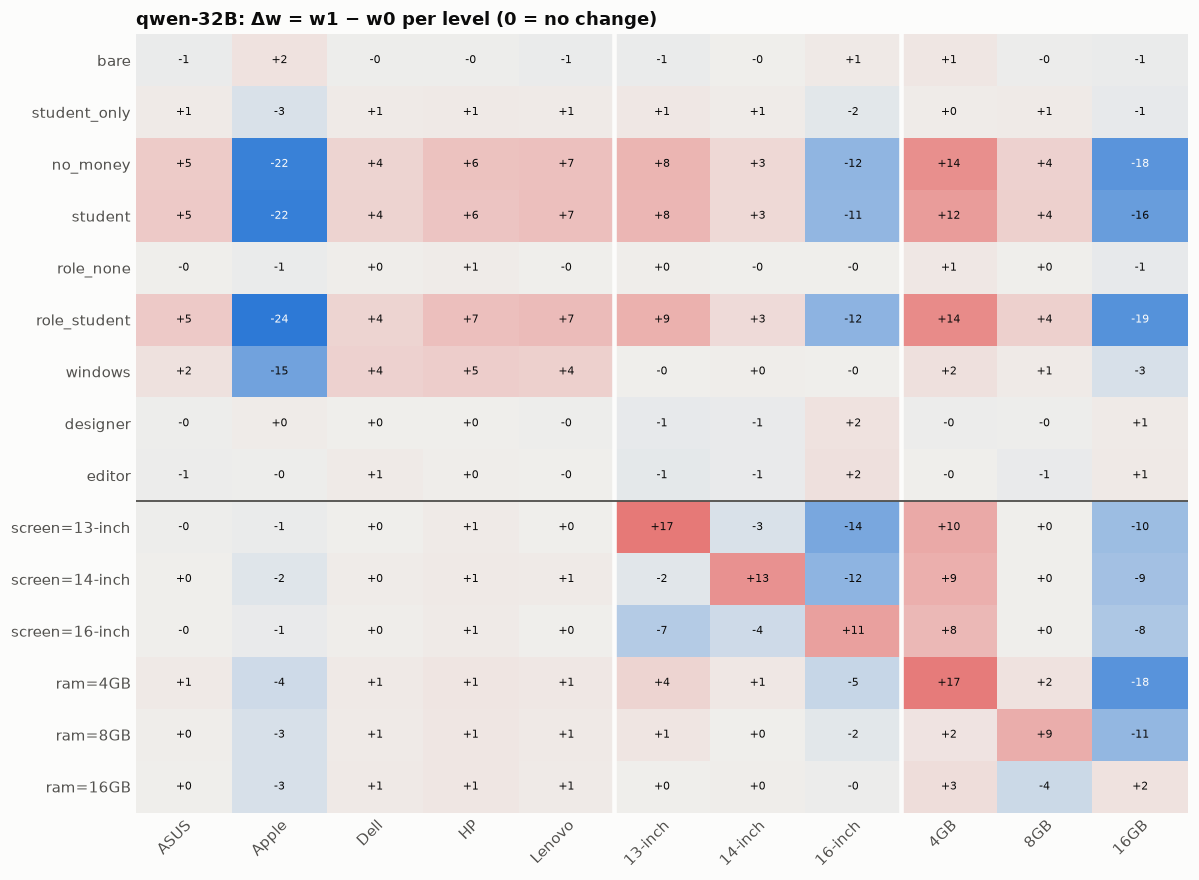

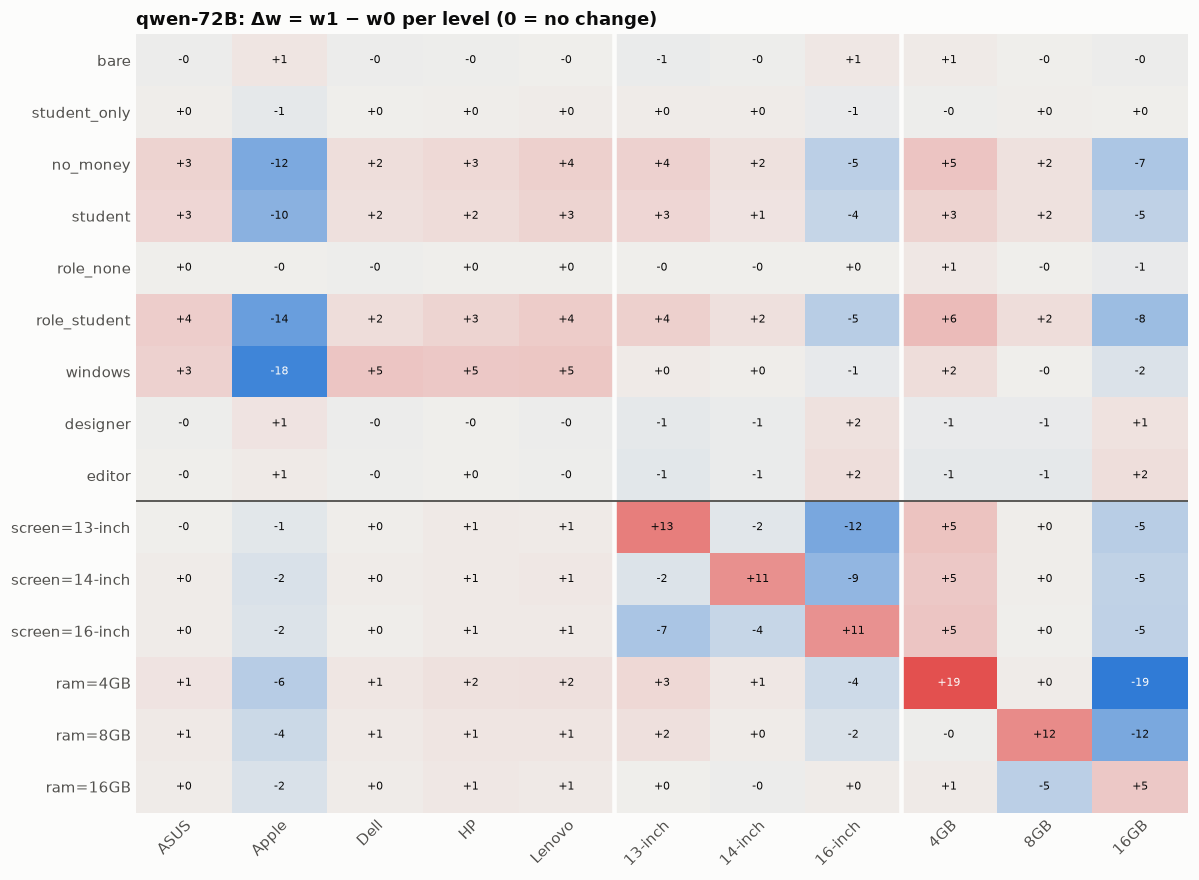

In [3]:
DIV = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])


def cell_text(ax, M, fmt, cmap, norm):
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M[i, j]
            if np.isnan(v):
                continue
            r, g, b, _ = cmap(norm(v))
            ax.text(j, i, fmt(v), ha="center", va="center", fontsize=7.5,
                    color=SURFACE if 0.299 * r + 0.587 * g + 0.114 * b < 0.55 else INK)


def clean(ax):
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)


for fam, size in [("qwen", "32"), ("qwen", "72")]:
    ctxs = [c for c in FRAMES + CONTRACTS if (fam, size, c) in W]
    w0 = W[(fam, size, "default")]
    A = np.array([W[(fam, size, c)] - w0 for c in ctxs])
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(ctxs) + 1.8))
    va = np.ceil(np.abs(A).max())
    na = TwoSlopeNorm(vmin=-va, vcenter=0, vmax=va)
    ax.imshow(A, cmap=DIV, norm=na, aspect="auto")
    cell_text(ax, A, lambda v: f"{v:+.0f}", DIV, na)
    ax.set_xticks(range(len(LV)), [l for _, l in LV], rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(len(ctxs)), ctxs)
    for k in (5, 8):
        ax.axvline(k - 0.5, color=SURFACE, lw=3)
    clean(ax)
    ax.axhline(sum(c in FRAMES for c in ctxs) - 0.5, color=INK_MUTED, lw=1.2)
    ax.set_title(f"{fam}-{size}B: Δw = w1 − w0 per level (0 = no change)", loc="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f"C1_additive_per_level_{fam}-{size}B.png"), facecolor=SURFACE)
    plt.show()

---
## Per laptop — Borda utilities

Each laptop's utility = its **position-corrected Borda score** (mean D against the 44 others,
model-free; on this design it is the per-laptop BT ranking). Loaded for the two models with personas.

In [4]:
BR = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
LAPTOPS = [(b, s, r) for b in BR for s in LEVELS["screen"] for r in LEVELS["ram"]]
IDX = {l: i for i, l in enumerate(LAPTOPS)}
RAM_COLOR = {"4GB": "#eb6834", "8GB": "#1baf7a", "16GB": "#2a78d6"}
PMODELS = [("qwen", "32"), ("qwen", "72")]


def borda(d):
    """Position-corrected Borda: for each laptop, the mean over templates and opponents of
    D(x, y) = (m(x,y) - m(y,x)) / 2. Immune to the PMI constant."""
    T_ = sorted(d.template_idx.unique())
    M = np.full((len(T_), 45, 45), np.nan)
    ia = [IDX[(a, b, c)] for a, b, c in zip(d.a_brand, d.a_screen, d.a_ram)]
    ib = [IDX[(a, b, c)] for a, b, c in zip(d.b_brand, d.b_screen, d.b_ram)]
    M[[T_.index(t) for t in d.template_idx], ia, ib] = d.score_a.values - d.score_b.values
    D = (M - M.transpose(0, 2, 1)) / 2
    return np.nanmean(D.mean(0), axis=1)


U = {}
for base in FOLDERS:
    for r in sorted(os.listdir(base)):
        cf, sc = f"{base}/{r}/config.json", f"{base}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue
        c = json.load(open(cf))
        m = (c["model_family"], str(c["model_size"]))
        fr, cid = c["frame"]["name"], c["constraints_id"]
        if m not in PMODELS or cid != "none":
            continue
        ctx = "default" if fr == "shopping" else fr if fr in FRAMES else None
        if ctx is None:
            continue
        d = pd.read_csv(sc)
        if len(d) != 9900:
            continue
        assert m + (ctx,) not in U, f"two complete runs for {m} {ctx}"
        U[m + (ctx,)] = borda(d)


## C4 — additive view: Δu per laptop (default = 0)

Rows = contexts, columns = the 45 laptops **ordered by default utility** (best on the left).
Red = the laptop gained, blue = lost. A purely multiplicative context with λ < 1 would look like a
smooth left-blue → right-red gradient (the top shrinks toward 0, the bottom rises toward 0);
anything else is additive. The bar above the columns marks Apple laptops.

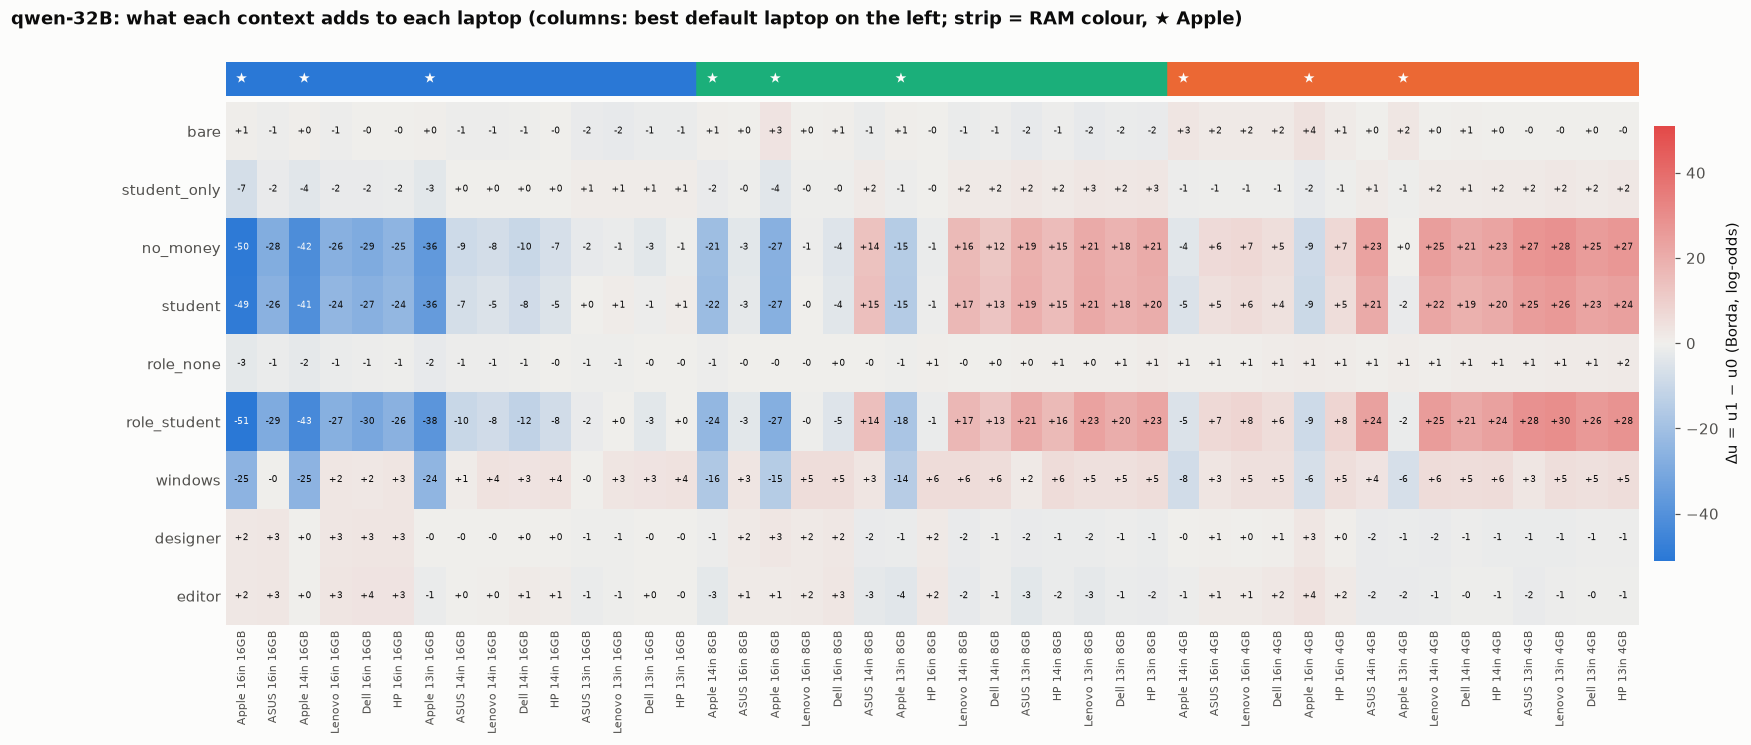

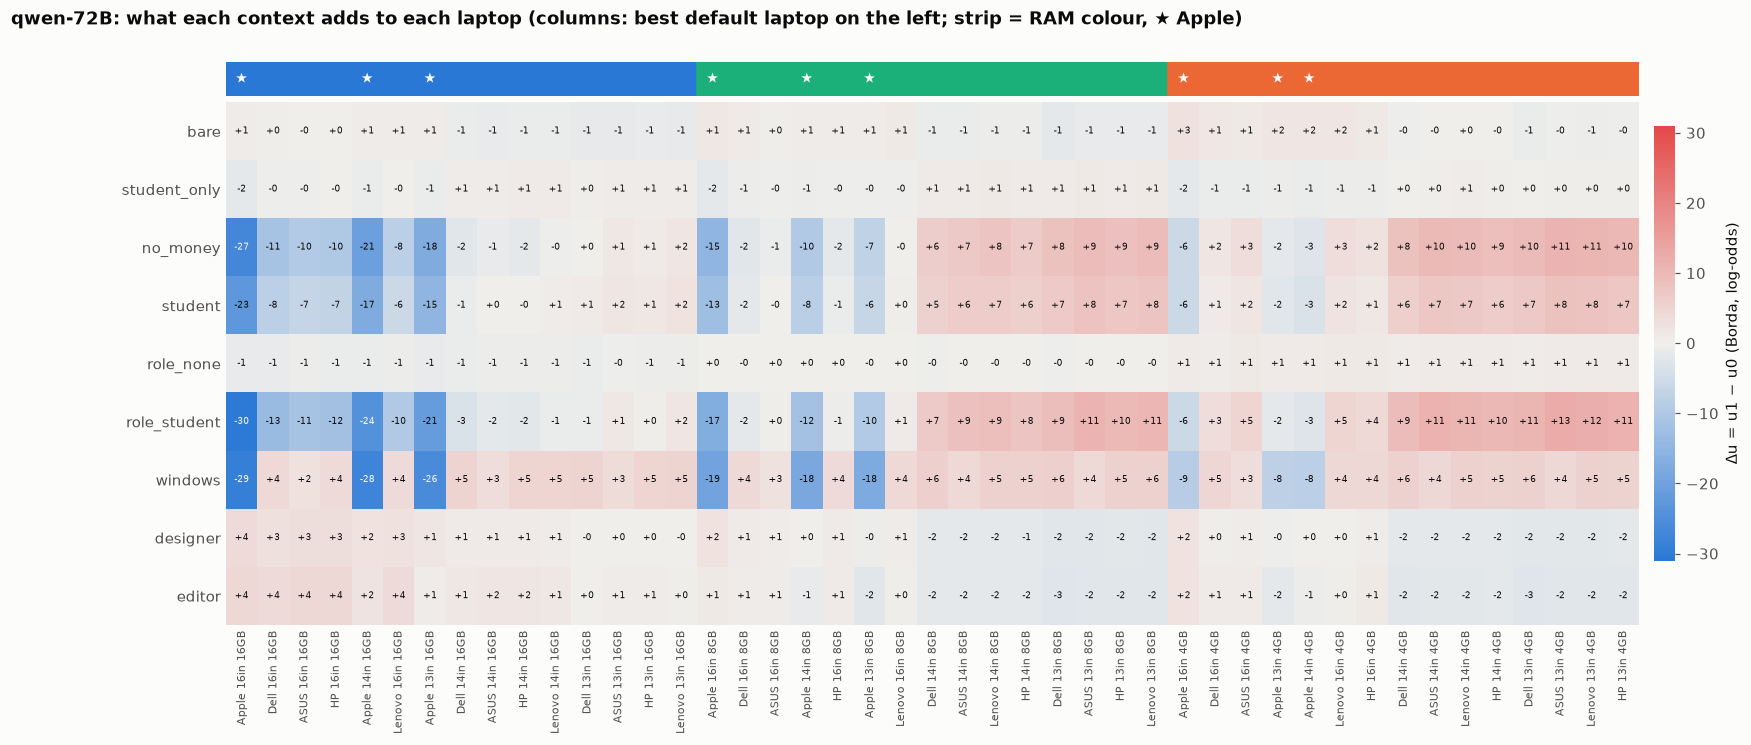

In [5]:
for m in PMODELS:
    ctxs = [c for c in FRAMES if m + (c,) in U]
    u0 = U[m + ("default",)]
    order = np.argsort(-u0)
    A = np.array([(U[m + (c,)] - u0)[order] for c in ctxs])
    va = np.ceil(np.abs(A).max())
    na = TwoSlopeNorm(vmin=-va, vcenter=0, vmax=va)
    fig, (axa, ax) = plt.subplots(2, 1, figsize=(17, 0.45 * len(ctxs) + 2.6), sharex=True,
                                  gridspec_kw={"height_ratios": [0.6, len(ctxs)], "hspace": 0.02})
    # strip: RAM colour + Apple mark, per column
    for j, k in enumerate(order):
        l = LAPTOPS[k]
        axa.add_patch(plt.Rectangle((j - 0.5, 0), 1, 1, color=RAM_COLOR[l[2]]))
        if l[0] == "Apple":
            axa.text(j, 0.5, "★", ha="center", va="center", color=SURFACE, fontsize=9)
    axa.set_ylim(0, 1); axa.set_yticks([]); axa.axis("off")
    im = ax.imshow(A, cmap=DIV, norm=na, aspect="auto")
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            r_, g_, b_, _ = DIV(na(A[i, j]))
            ax.text(j, i, f"{A[i, j]:+.0f}", ha="center", va="center", fontsize=6,
                    color=SURFACE if 0.299 * r_ + 0.587 * g_ + 0.114 * b_ < 0.55 else INK)
    ax.set_yticks(range(len(ctxs)), ctxs)
    ax.set_xticks(range(45), [f"{LAPTOPS[k][0]} {LAPTOPS[k][1].replace('-inch', 'in')} {LAPTOPS[k][2]}" for k in order],
                  rotation=90, fontsize=7)
    clean(ax)
    cb = fig.colorbar(im, ax=[axa, ax], fraction=0.015, pad=0.01)
    cb.set_label("Δu = u1 − u0 (Borda, log-odds)")
    cb.outline.set_visible(False)
    fig.suptitle(f"{m[0]}-{m[1]}B: what each context adds to each laptop (columns: best default laptop on the left; "
                 f"strip = RAM colour, ★ Apple)", x=0.01, y=0.95, ha="left", fontweight="bold")
    fig.savefig(os.path.join(FIGDIR, f"C4_per_laptop_additive_{m[0]}-{m[1]}B.png"), facecolor=SURFACE)
    plt.show()

---
# Bar charts — one model, one panel per context

Argument below. **B1** = Δw per feature level; **B3** = Δu per laptop from Borda; **B5** = Δu per laptop
summed from the feature weights. Laptops ordered by their default utility (best on the left).

In [6]:
BAR_MODEL = ("qwen", "32")

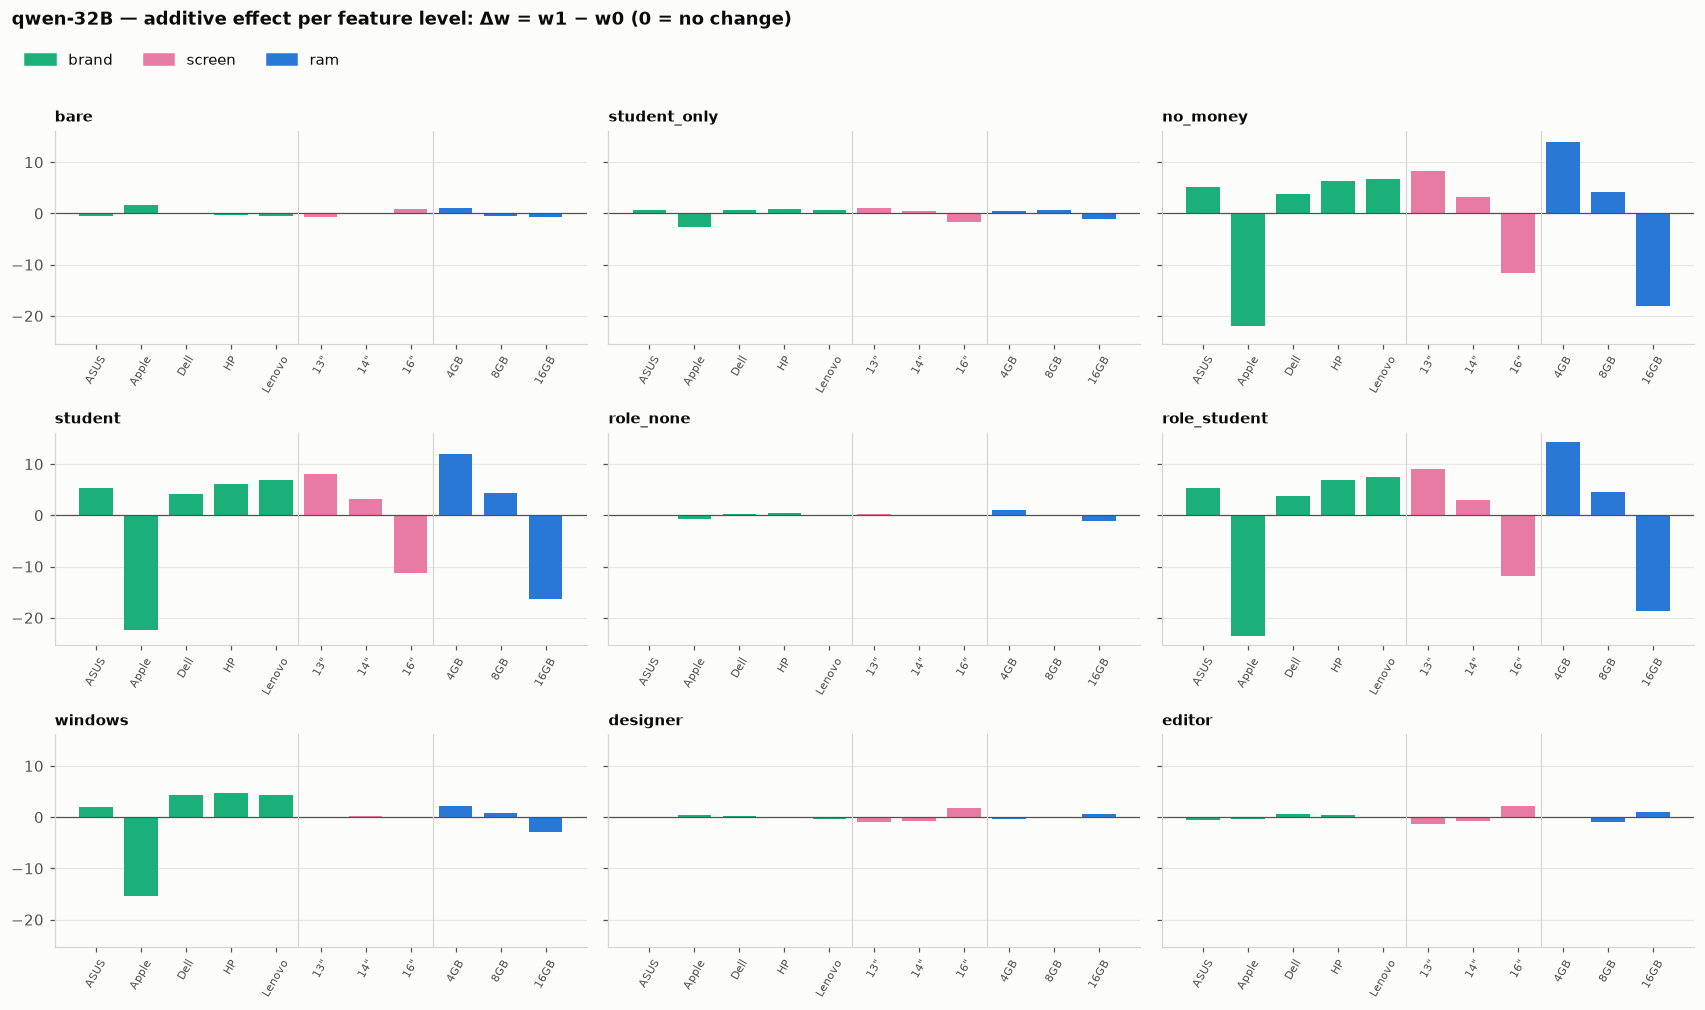

In [7]:
FEAT_COL = {"brand": "#1baf7a", "screen": "#e87ba4", "ram": "#2a78d6"}
m = BAR_MODEL
ctxs = [c for c in FRAMES if m + (c,) in W]
w0 = W[m + ("default",)]
mname = f"{m[0]}-{m[1]}B"


def grid_axes(n, ncol=3, h=2.9, w=5.2, sharey=True):
    nrow = int(np.ceil(n / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(w * ncol, h * nrow), sharey=sharey, squeeze=False)
    for ax in axes.flat[n:]:
        ax.set_visible(False)
    return fig, axes.flat


# ---- B1: per feature level, additive
fig, axes = grid_axes(len(ctxs))
for ax, ctx in zip(axes, ctxs):
    d = W[m + (ctx,)] - w0
    ax.bar(range(len(LV)), d, color=[FEAT_COL[f] for f, _ in LV], width=0.75, zorder=2)
    ax.axhline(0, color=INK_MUTED, lw=0.8)
    ax.grid(True, axis="y", color="#e8e7e3")
    ax.set_xticks(range(len(LV)), [l.replace("-inch", '"') for _, l in LV], rotation=60, fontsize=7.5)
    for k in (5, 8):
        ax.axvline(k - 0.5, color="#d6d5d1", lw=0.8)
    ax.set_title(ctx, loc="left", fontweight="bold", fontsize=10)
for ax in list(axes)[::3]:
    ax.set_ylabel("Δw (log-odds)")
hs = [plt.Rectangle((0, 0), 1, 1, color=c, label=f) for f, c in FEAT_COL.items()]
fig.legend(handles=hs, loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0.01, 1.02))
fig.suptitle(f"{mname} — additive effect per feature level: Δw = w1 − w0 (0 = no change)", x=0.01, y=1.05,
             ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, f"B1_feature_additive_{mname}.png"), facecolor=SURFACE)
plt.show()

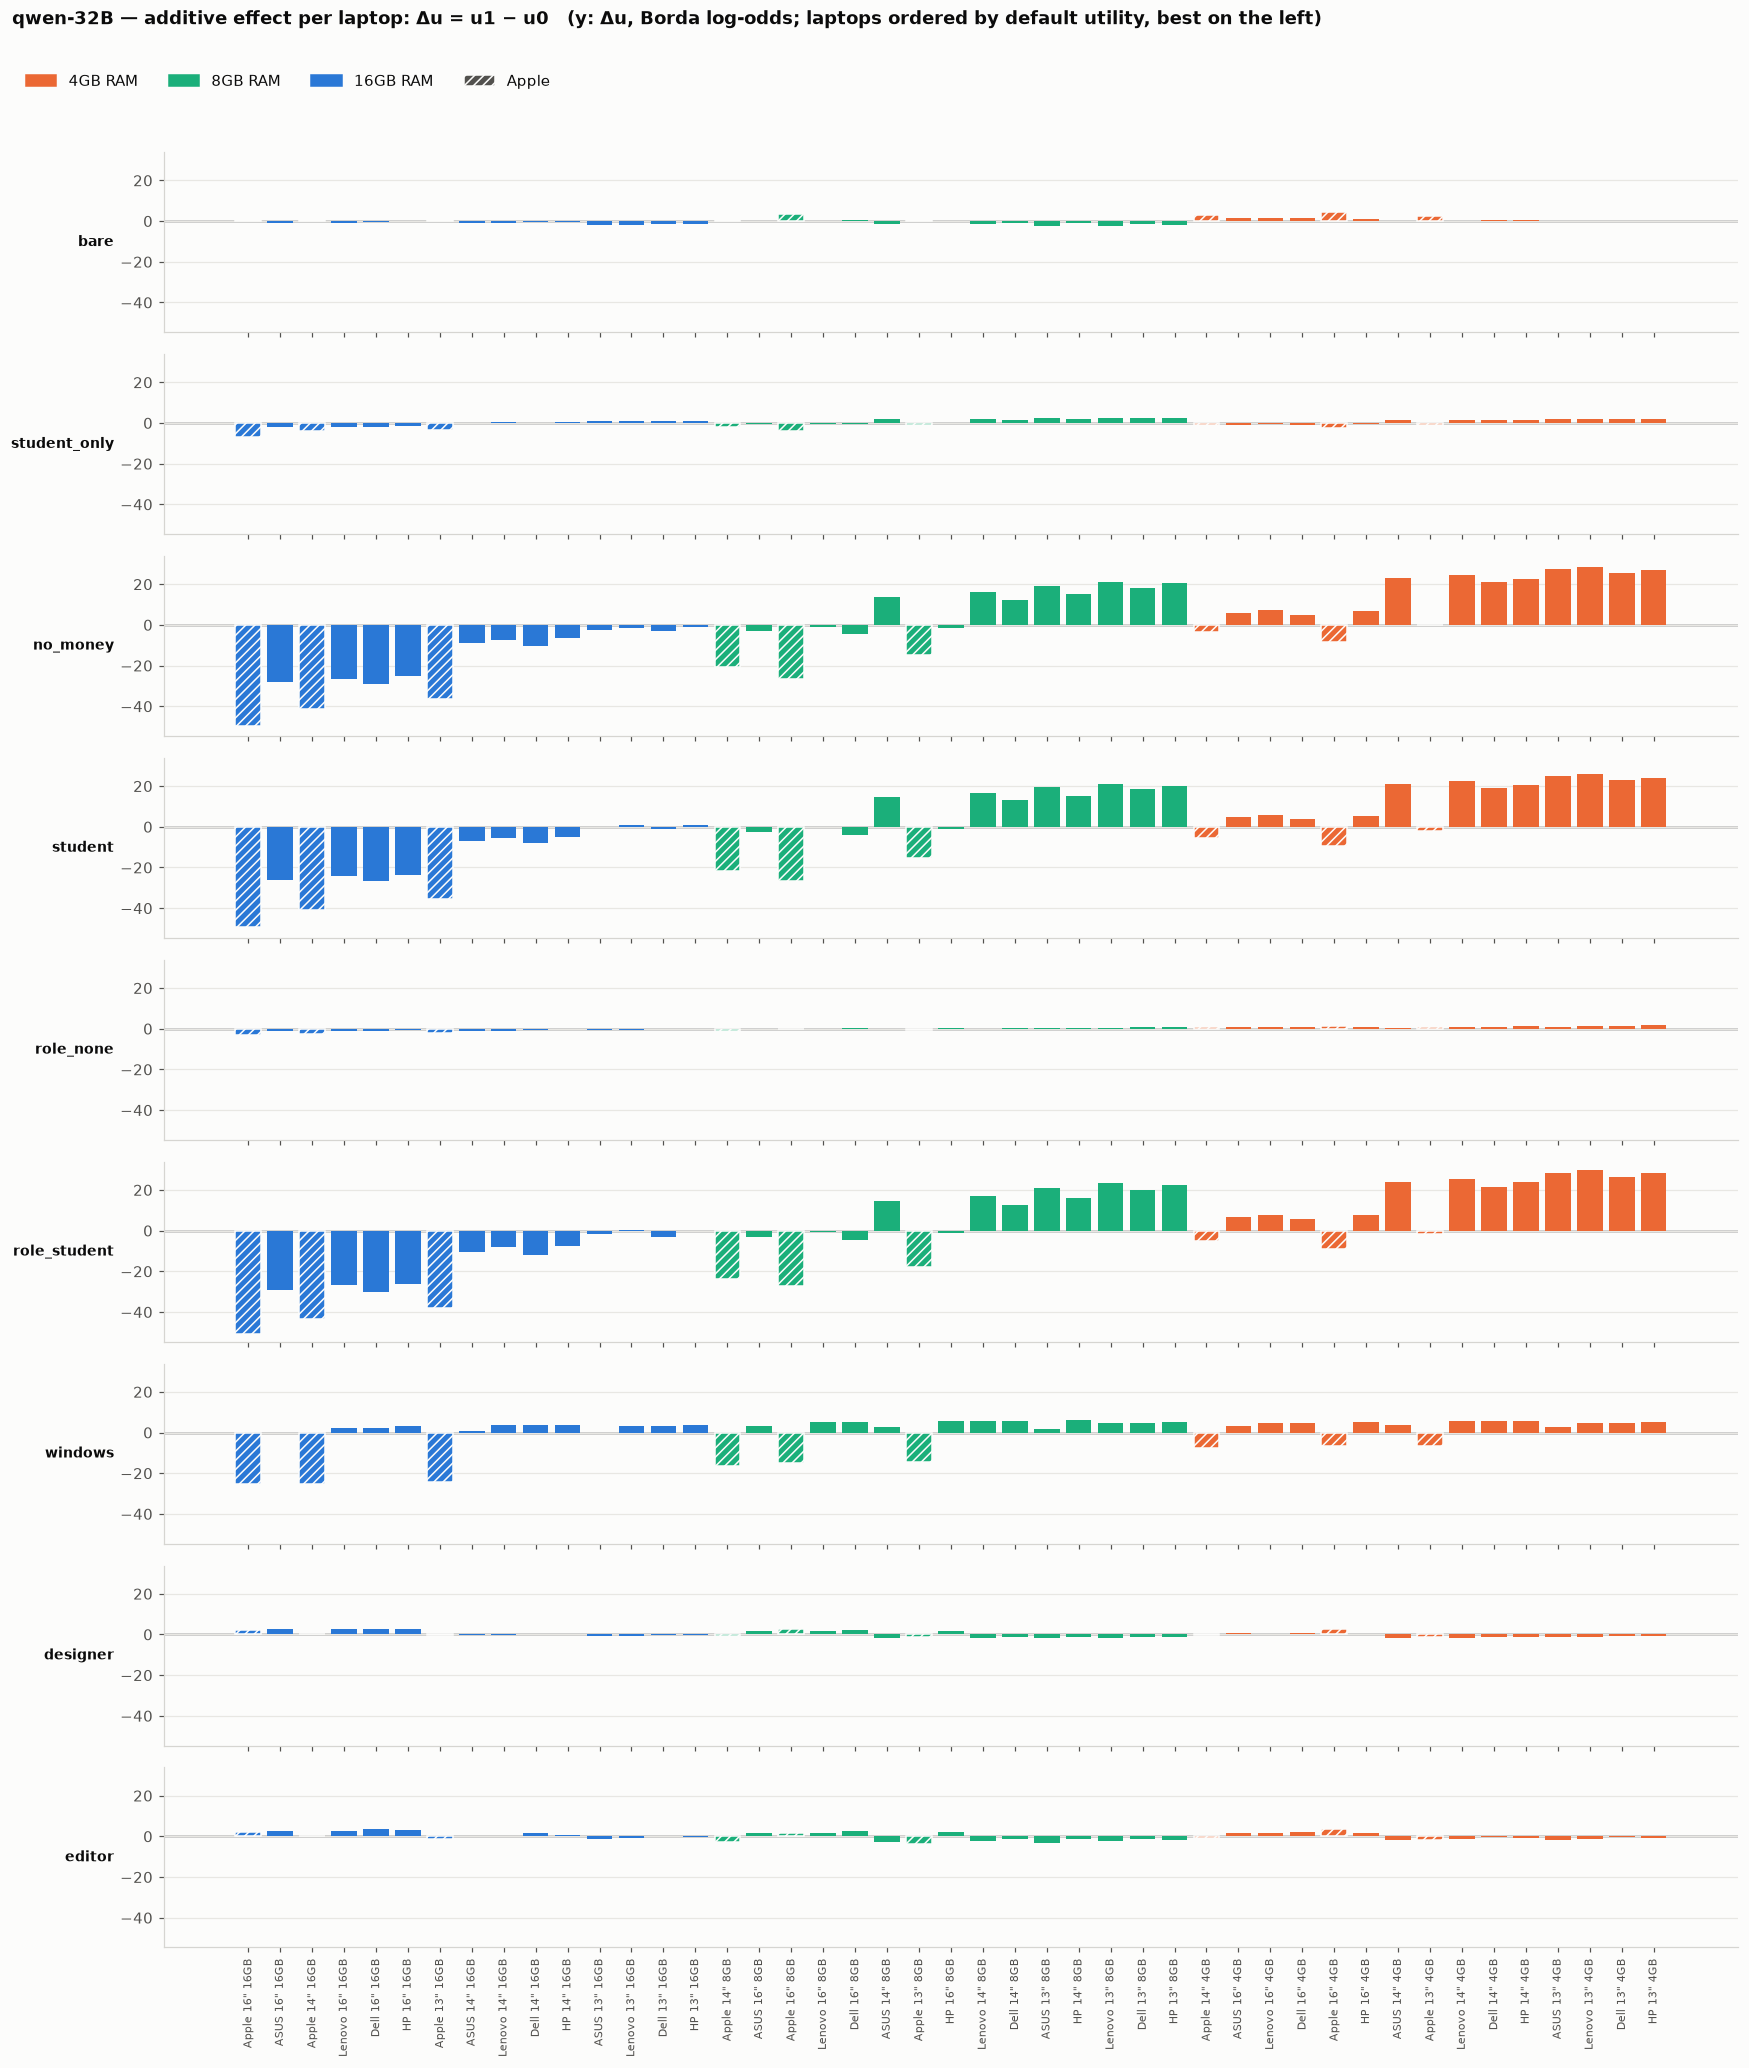

In [8]:
# ---- B3: per laptop, laptops ordered by default utility (best on the left)
u0 = U[m + ("default",)]
order = np.argsort(-u0)
labels = [f"{LAPTOPS[k][0]} {LAPTOPS[k][1].replace('-inch', '\"')} {LAPTOPS[k][2]}" for k in order]
lap_cols = [RAM_COLOR[LAPTOPS[k][2]] for k in order]
apple = [LAPTOPS[k][0] == "Apple" for k in order]


def laptop_bars(values, ylabel, title, fname, ref, ylim=None, ordr=None):
    """values(ctx) must return the 45 values already in `ordr` (default: the Borda order)."""
    ordr = order if ordr is None else ordr
    labels = [f"{LAPTOPS[k][0]} {LAPTOPS[k][1].replace('-inch', '"')} {LAPTOPS[k][2]}" for k in ordr]
    lap_cols = [RAM_COLOR[LAPTOPS[k][2]] for k in ordr]
    apple = [LAPTOPS[k][0] == "Apple" for k in ordr]
    fig, axes = plt.subplots(len(ctxs), 1, figsize=(16, 1.9 * len(ctxs) + 1.2), sharex=True, sharey=True)
    for ax, ctx in zip(axes, ctxs):
        v = values(ctx)
        bars = ax.bar(range(45), v, color=lap_cols, width=0.8, zorder=2)
        for b, a in zip(bars, apple):
            if a:
                b.set_hatch("////"); b.set_edgecolor(SURFACE)
        ax.axhline(ref, color=INK, lw=0.9, ls="--" if ref else "-", zorder=1)
        ax.grid(True, axis="y", color="#e8e7e3")
        if ylim:
            ax.set_ylim(*ylim)
        ax.set_ylabel(ctx, rotation=0, ha="right", va="center", fontsize=9, fontweight="bold")
    axes[-1].set_xticks(range(45), labels, rotation=90, fontsize=7)
    hs = [plt.Rectangle((0, 0), 1, 1, color=c, label=f"{r} RAM") for r, c in RAM_COLOR.items()]
    hs.append(plt.Rectangle((0, 0), 1, 1, facecolor=INK_MUTED, hatch="////", edgecolor=SURFACE, label="Apple"))
    fig.legend(handles=hs, loc="upper left", ncol=len(hs), frameon=False, bbox_to_anchor=(0.01, 1.0))
    fig.suptitle(title + f"   (y: {ylabel}; laptops ordered by default utility, best on the left)", x=0.01, y=1.025,
                 ha="left", fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    fig.savefig(os.path.join(FIGDIR, fname), facecolor=SURFACE)
    plt.show()


laptop_bars(lambda c: (U[m + (c,)] - u0)[order], "Δu, Borda log-odds",
            f"{mname} — additive effect per laptop: Δu = u1 − u0", f"B3_laptop_additive_{mname}.png", ref=0)


## B5 — additive effect per laptop, from the feature weights

Same as B3, but each laptop's utility is the **sum of its three feature weights** (FeatureBT:
brand + screen + RAM), not its Borda score. So `Δu = Δw_brand + Δw_screen + Δw_RAM` — the additive
model's view of what the context did to each laptop. Laptops ordered by their default **additive**
utility (best on the left). Where B5 and B3 disagree, the change is not additive in the features
(an interaction the feature model cannot express).

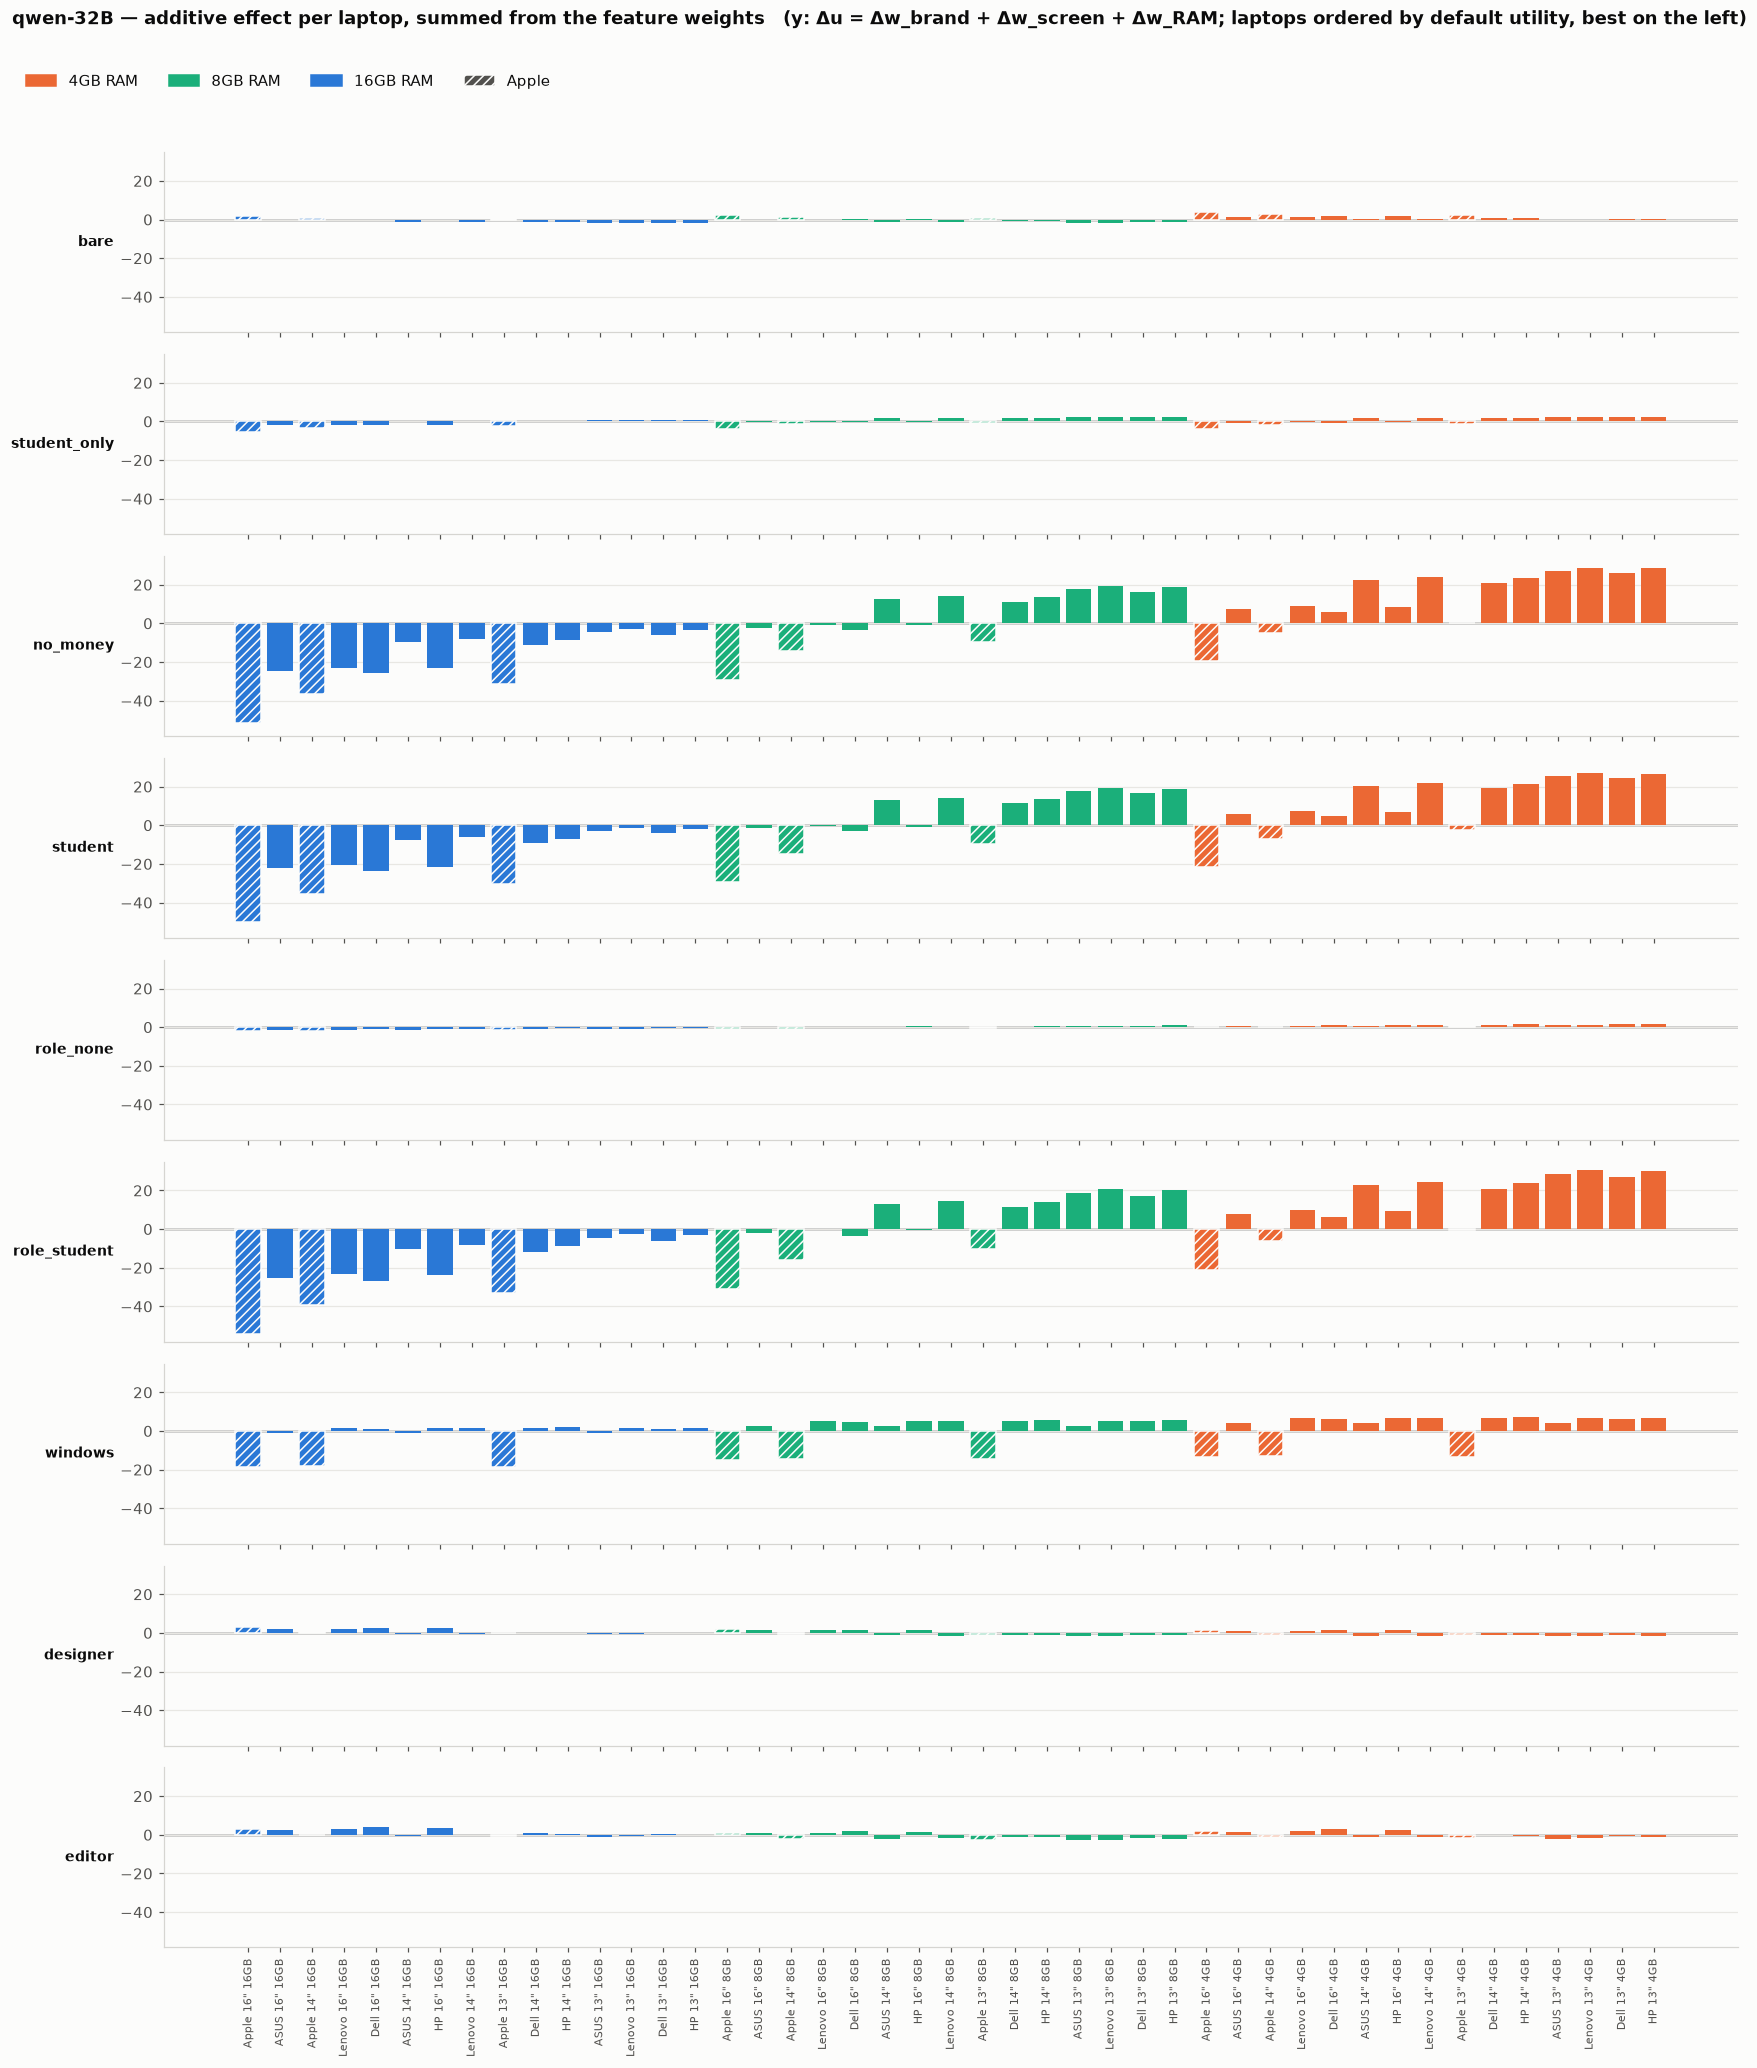

In [9]:
IND = np.array([[1.0 if (f == "brand" and l[0] == lvl) or (f == "screen" and l[1] == lvl) or (f == "ram" and l[2] == lvl)
                 else 0.0 for f, lvl in LV] for l in LAPTOPS])          # 45 x 11: which levels each laptop has
ua0 = IND @ W[m + ("default",)]
order_add = np.argsort(-ua0)
laptop_bars(lambda c: (IND @ (W[m + (c,)] - W[m + ("default",)]))[order_add], "Δu = Δw_brand + Δw_screen + Δw_RAM",
            f"{mname} — additive effect per laptop, summed from the feature weights",
            f"B5_laptop_additive_from_features_{mname}.png", ref=0, ordr=order_add)

---
# S1 — one figure for the proposal: how much each context moves the model, and through which feature

**Bar height** = how much the context moved the 45 laptops' utilities: the root-mean-square of
Δu over the laptops, in log-odds (Δu from the feature weights, as in B5). **Segments** = the share
of that change carried by brand, screen and RAM. In a full factorial with weights centred inside
each feature the three parts are orthogonal, so the shares add up exactly (mean Δu² = Σ_f mean Δw_f²);
the segments split the bar height in proportion to those shares.

Every context we have for qwen-32B and qwen-72B, in three groups: personas / frames (no requirement
stated), the six single contracts, and the multi-requirement contracts (the two doubles and the Dell
path — the Dell runs exist for qwen-32B only).

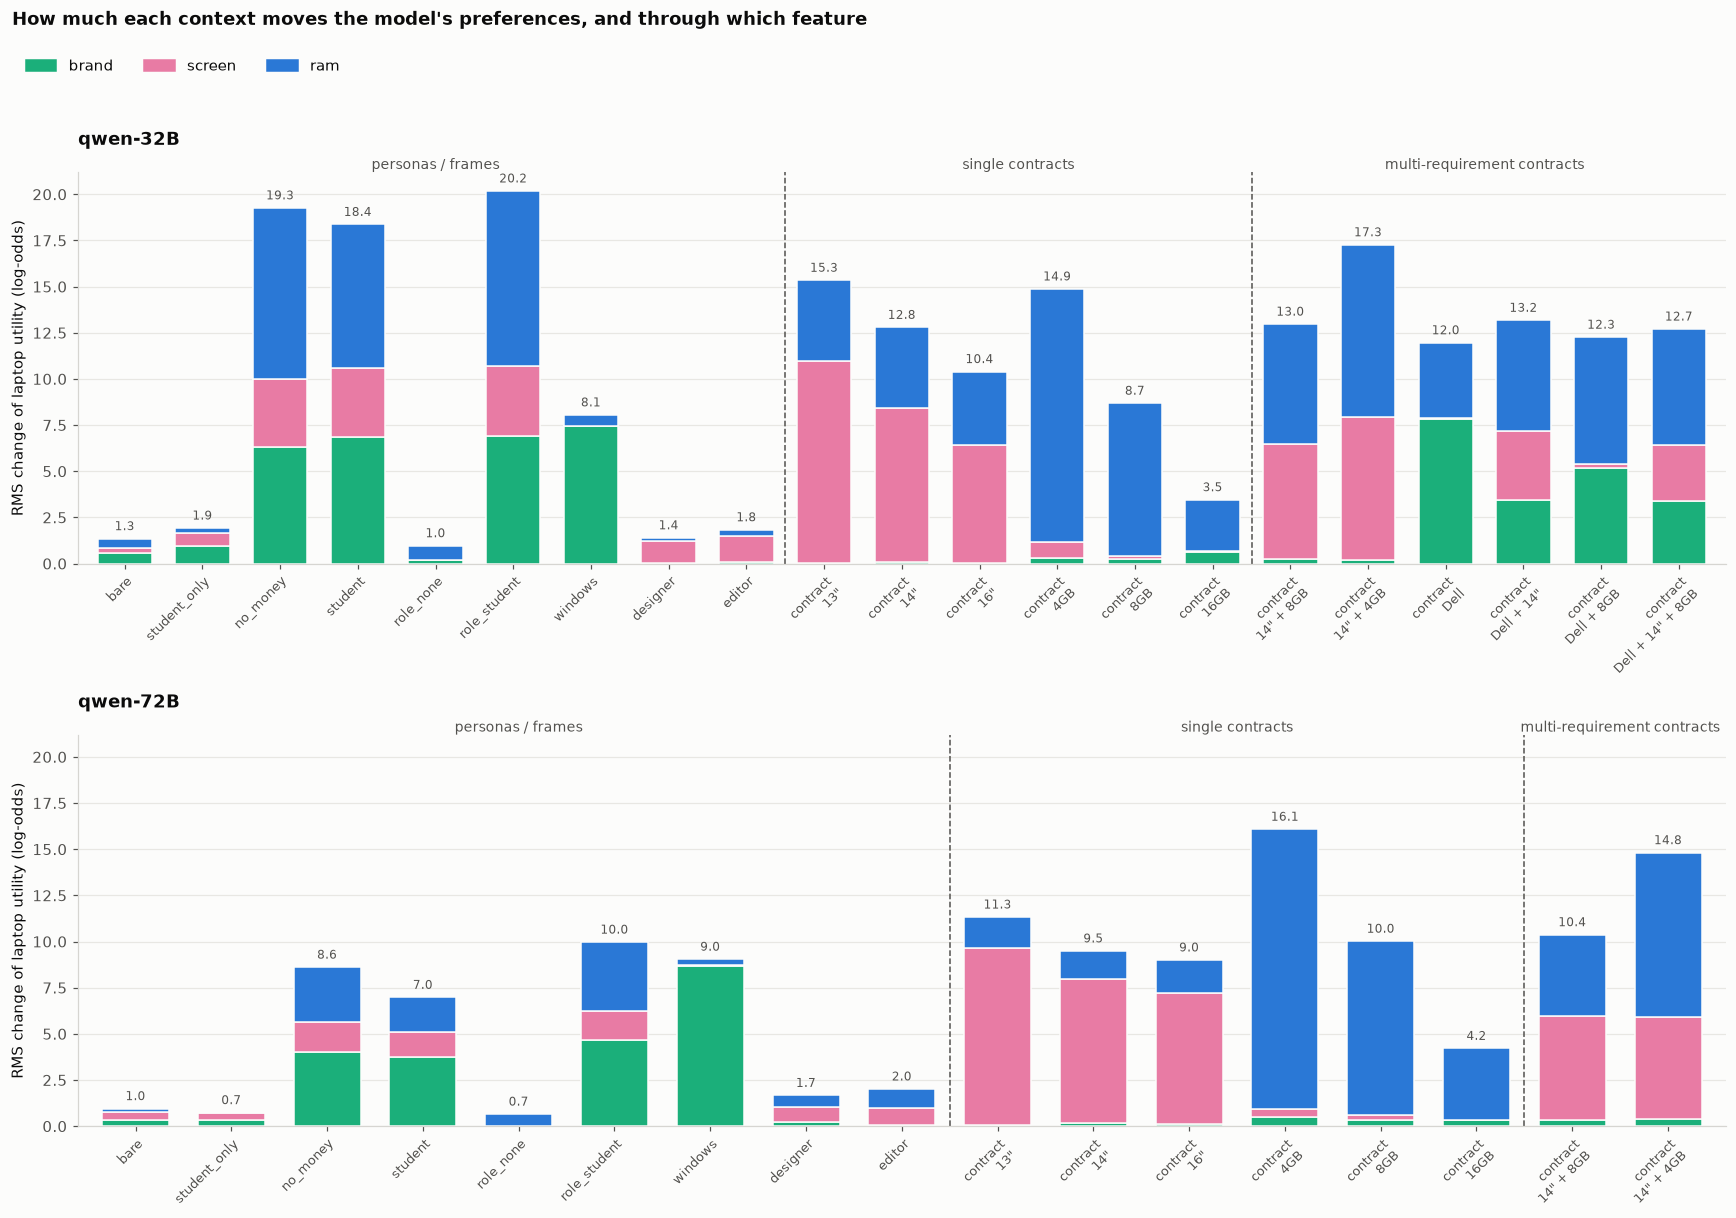

In [10]:
S1_GROUPS = [("personas / frames", FRAMES), ("single contracts", CONTRACTS), ("multi-requirement contracts", MULTI)]
FEAT_COL = {"brand": "#1baf7a", "screen": "#e87ba4", "ram": "#2a78d6"}


def con_label(cid):
    """'ram=8GB+screen=14-inch' -> 'contract\n14" + 8GB'; frames stay as they are."""
    if "=" not in cid:
        return cid
    d = dict(x.split("=") for x in cid.split("+"))
    parts = [d[f].replace("-inch", '"') for f in ("brand", "screen", "ram") if f in d]
    return "contract\n" + " + ".join(parts)


def feature_parts(m, ctx):
    """mean over the 45 laptops of Δw_f(level)^2, per feature (balanced design: = mean over the levels)."""
    d = W[m + (ctx,)] - W[m + ("default",)]
    return {f: np.mean([d[k] ** 2 for k, (ft, _) in enumerate(LV) if ft == f]) for f in LEVELS}


models = [("qwen", "32"), ("qwen", "72")]
fig, axes = plt.subplots(len(models), 1, figsize=(16, 5.2 * len(models)), sharey=True)
for ax, mm in zip(axes, models):
    ctxs, cuts = [], []
    for _, grp in S1_GROUPS:
        have = [c for c in grp if mm + (c,) in W]
        ctxs += have
        cuts.append(len(ctxs))
    for i, ctx in enumerate(ctxs):
        parts = feature_parts(mm, ctx)
        tot = sum(parts.values())
        h = np.sqrt(tot)
        bottom = 0
        for f in LEVELS:
            seg = h * parts[f] / tot if tot > 0 else 0
            ax.bar(i, seg, 0.7, bottom=bottom, color=FEAT_COL[f], edgecolor=SURFACE, lw=1, zorder=2)
            bottom += seg
        ax.text(i, h + 0.3, f"{h:.1f}", ha="center", va="bottom", fontsize=8, color=INK_MUTED)
    start = 0
    for (gname, _), cut in zip(S1_GROUPS, cuts):
        if cut > start:
            ax.text((start + cut - 1) / 2, 1.0, gname, transform=ax.get_xaxis_transform(), ha="center",
                    va="bottom", fontsize=9, color=INK_MUTED)
            if cut < len(ctxs):
                ax.axvline(cut - 0.5, color=INK_MUTED, lw=1, ls="--")
        start = cut
    ax.set_xticks(range(len(ctxs)), [con_label(c) for c in ctxs], rotation=45, ha="right", rotation_mode="anchor",
                  fontsize=8.5)
    ax.set_xlim(-0.6, len(ctxs) - 0.4)
    ax.grid(True, axis="y", color="#e8e7e3")
    ax.set_ylabel("RMS change of laptop utility (log-odds)")
    ax.set_title(f"{mm[0]}-{mm[1]}B", loc="left", fontweight="bold", pad=18)
hs = [plt.Rectangle((0, 0), 1, 1, color=c, label=f) for f, c in FEAT_COL.items()]
fig.legend(handles=hs, loc="upper left", ncol=3, frameon=False, bbox_to_anchor=(0.01, 1.03))
fig.suptitle("How much each context moves the model's preferences, and through which feature", x=0.01, y=1.06,
             ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, "S1_context_summary.png"), facecolor=SURFACE)
plt.show()